# 4 · Checking the model, and the upscaling check

**KAI-GeoEnergy · KAI Reservoir Lab · Utah FORGE, Milford, Utah (USA)**

**Questions.**
1. Is the +24 °C produced-temperature misfit of notebook 3 in the wellbore or in the reservoir?
2. Do the 2024 tracers travel between the wells as fast as the model says?
3. With apertures that open and close with pressure, which rates can the well pair run without exceeding the minimum horizontal stress?
4. Does keeping the full fracture permeability tensor (not only its diagonal) change the answers?
5. **The upscaling check.** How much does a coarse model, the usual industry practice, change the breakthrough time against the fine model? With a P10–P90 over the ensemble.

**New data** (DOE Geothermal Data Repository, CC BY 4.0; `data/` holds only derived values, rebuilt by `rebuild_data.py`):
* **Tracers** (GDR 1701, Guo, Oliver and Shokanov 2024, DOI [10.15121/2507443](https://doi.org/10.15121/2507443)): ten nanoparticle tracers injected into 16A(78)-32 every other day from 11 August 2024, sampled at 16B(78)-32.
* **Fibre temperatures** in 16B (GDR 1721, Neubrex): distributed temperature sensing (DTS) on 4 August (before the test) and 12–16 August 2024 (during it).

The 2024 circulation tests, trajectories and fracture data are those of notebooks 2 and 3. *Credit: Utah FORGE, U.S. Department of Energy, via the Geothermal Data Repository (OpenEI), CC BY 4.0.*

**What changed in the model since notebook 3.**
* Bottom-hole pressures and the injection temperature now come from a **wellbore model**. It uses Hasan–Kabir heat loss and single-phase friction along the surveyed trajectories, with the notebook 1 temperature model as the geotherm.
* The stimulated fractures have **Barton–Bandis apertures**. Their effective normal stress is Shmin − p. The calibrated apertures are the apertures at the August 2024 pressures. The fractures can close or open up to their unloaded width; no new fractures are created.
* The forecasts are run **the way the 2024 test was**: 16A at a rate, 16B at its August bottom-hole pressure. A rate is pressure-feasible when 16A stays at or below Shmin for 30 years.
* The ensemble has two more uncertain inputs, the Barton–Bandis stiffness and maximum closure.

**Labels.** Every model number is **simulated** by the KAI Reservoir Lab engine (`results/kai_engine_phase4.json`). Data-derived numbers are recomputed here with the MIT helpers in `forge_tools.py`; the notebook stops if the engine disagrees.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import forge_tools as ft
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight", "savefig.facecolor": "white"})
GOLD, CHARCOAL, GRANITE, BLUE, GREY = "#c9a227", "#26292e", "#b5838d", "#2a78d6", "#8a8f98"     # KAI energy palette
pathlib.Path("results").mkdir(exist_ok=True); pathlib.Path("figures").mkdir(exist_ok=True)
E = json.loads(pathlib.Path("results/kai_engine_phase4.json").read_text())      # KAI engine run (simulated)
ens = E["ensemble"]
def pct(d, f="{:.1f}"):
    fm = lambda v: v if isinstance(v, str) else f.format(v)
    return f"{fm(d['P50'])} ({fm(d['P10'])}–{fm(d['P90'])})"
print(E["label"]); print(f"ensemble: {ens['members'] - ens['failed']}/{ens['members']} members ran, {ens['calibration_converged']} calibrated")

simulated (KAI Reservoir Lab TPFA solver, equivalent-continuum fractured granite); not field data
ensemble: 20/20 members ran, 20 calibrated


## 1 · The wellbore: where the temperature misfit is

The 16B wellhead temperature (189.8 °C over days 14–26, the in-line reading corrected with the manual gun) is turned into a bottom-hole temperature with the wellbore model. The table shows the P10–P90 over rock and cement conductivity, hole size, geotherm offset (±10 °C) and the gun correction (P10–P90 of 73 checks).

In [2]:
W = E["wellbore"]
rows = [
    {"quantity": "cooling from bottom hole to wellhead, 24.5 kg/s (°C)", "P50 (P10–P90)": pct(W["cooling_implied_c"])},
    {"quantity": "bottom-hole temperature implied by the measured wellhead (°C)", "P50 (P10–P90)": pct(W["T_bottom_implied_c"])},
    {"quantity": "producer bottom-hole pressure from 1.73 MPa at the wellhead (MPa)", "P50 (P10–P90)": pct(W["producer_bhp_mpa"], "{:.2f}")},
    {"quantity": "injector bottom-hole pressure from 19.6 MPa at the wellhead (MPa)", "P50 (P10–P90)": pct(W["injector_bhp_mpa"], "{:.2f}")},
    {"quantity": "injector bottom-hole temperature from 25 °C pit water (°C)", "P50 (P10–P90)": pct(W["injector_T_bottom_c"])},
]
display(pd.DataFrame(rows))
V = ens["validation"]
for kind in ("constant_apertures", "barton_bandis"):
    print(f"{kind.replace('_', ' ')}: model bottom-hole {pct(V[kind]['produced_T_bottomhole_c'])} °C; "
          f"misfit against the implied bottom-hole value {pct(V[kind]['T_misfit_bottomhole_c'], '{:+.1f}')} °C")

,quantity,P50 (P10–P90)
0,"cooling from bottom hole to wellhead, 24.5 kg/...",13.4 (12.3–14.4)
1,bottom-hole temperature implied by the measure...,202.9 (200.0–205.9)
2,producer bottom-hole pressure from 1.73 MPa at...,21.95 (21.89–22.01)
3,injector bottom-hole pressure from 19.6 MPa at...,42.85 (42.85–42.86)
4,injector bottom-hole temperature from 25 °C pi...,42.0 (41.2–44.2)


constant apertures: model bottom-hole 214.0 (212.6–215.5) °C; misfit against the implied bottom-hole value +11.2 (+9.7–+12.6) °C
barton bandis: model bottom-hole 214.1 (212.6–215.5) °C; misfit against the implied bottom-hole value +11.2 (+9.7–+12.6) °C


### The fibre temperatures (DTS)

The DTS files are checked before they are used. During the test the profile has a step of 80–90 °C between 2,800 and 3,200 ft. Above the step, readings drift by up to 66 °C in four days. Below it, the profile is smooth (spread over a day about 0.2 °C). So only the shape of the deep section can be compared, not its level.

step: 2800–3200 ft, 80 °C; deep section 3,200–9,240 ft: +18.4 °C (9.8 °C per km of hole)
wellbore model over the same section, day 7: +5.8 (5.1–6.6) °C; no completion resistance and λ = 3.2 W/m/K (an upper bound): +7.2 (5.9–8.2) °C


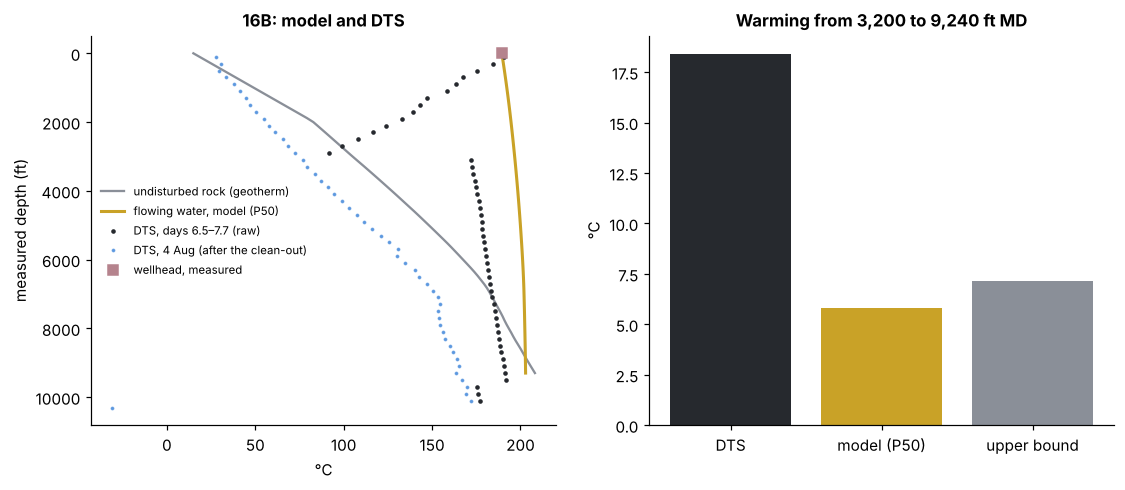

In [3]:
dts = pd.read_csv("data/dts_16B_2024.csv"); deep = json.loads(pathlib.Path("data/dts_16B_2024_deep.json").read_text())
D = E["dts"]
assert abs(deep["slope_c_per_km_md"] - D["deep"]["slope_c_per_km_md"]) < 1e-3 and abs(deep["T_bottom_c"] - D["deep"]["T_bottom_c"]) < 1e-3
jump = np.abs(np.diff(dts.flowing_days_6p5_7p7_c.values)); k = int(np.nanargmax(jump))
assert dts.md_ft[k] == D["step_md_ft"][0]
dT_dts = deep["T_bottom_c"] - deep["T_top_c"]
print(f"step: {dts.md_ft[k]:.0f}–{dts.md_ft[k + 1] + 200:.0f} ft, {jump[k]:.0f} °C; deep section 3,200–9,240 ft: +{dT_dts:.1f} °C "
      f"({deep['slope_c_per_km_md']:.1f} °C per km of hole)")
print(f"wellbore model over the same section, day 7: +{pct(W['dts_section_delta_model_c'])} °C; "
      f"no completion resistance and λ = 3.2 W/m/K (an upper bound): +{pct(W['dts_section_delta_upper_bound_c'])} °C")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
pr = W["profile_p50"]
ax[0].plot(pr["T_e"], np.array(pr["md_m"]) / ft.FT, color=GREY, label="undisturbed rock (geotherm)")
ax[0].plot(pr["T_c"], np.array(pr["md_m"]) / ft.FT, color=GOLD, lw=2, label="flowing water, model (P50)")
ax[0].plot(dts.flowing_days_6p5_7p7_c, dts.md_ft + 100, ".", color=CHARCOAL, ms=4, label="DTS, days 6.5–7.7 (raw)")
ax[0].plot(dts.static_4aug_c, dts.md_ft + 100, ".", color=BLUE, ms=3, alpha=0.6, label="DTS, 4 Aug (after the clean-out)")
ax[0].plot(E["tests"]["T_16B_wellhead_c"] if "tests" in E else 189.8, 0, "s", color=GRANITE, label="wellhead, measured")
ax[0].invert_yaxis(); ax[0].set_xlabel("°C"); ax[0].set_ylabel("measured depth (ft)"); ax[0].set_title("16B: model and DTS"); ax[0].legend(fontsize=7.5)
labels = ["DTS", "model (P50)", "upper bound"]
vals = [dT_dts, W["dts_section_delta_model_c"]["P50"], W["dts_section_delta_upper_bound_c"]["P50"]]
ax[1].bar(labels, vals, color=[CHARCOAL, GOLD, GREY])
ax[1].set_ylabel("°C"); ax[1].set_title("Warming from 3,200 to 9,240 ft MD")
fig.savefig("figures/forge_wellbore_16B.png")

**Reading it.** Between 3,200 and 9,240 ft, the DTS warms 2.6 times as much as the energy-balance upper bound allows. That bound has no completion resistance and the highest rock conductivity. A fluid flowing at 24.5 kg/s cannot lose that much heat to rock that is at most at the geotherm. The deep gradient is therefore not the fluid's. A depth-proportional error is what uncorrected differential attenuation in a Raman DTS looks like. With the step and the drift, we do not use the DTS absolute values. We state this as a limit of the data, not as a model fit. The 4 August profile was taken right after the clean-out of 1–4 August, so it is not the undisturbed geotherm either.

The wellbore model explains about 13 °C of the 24 °C misfit of notebook 3. **About 11 °C is left in the reservoir model** (see *what this says* below).

## 2 · Tracers: travel time between the wells

Tracers 1–3 arrived after 34, 64 and 16 hours, while the fractures were still filling (the report's reading). From tracer 4 on, every first detection was at the first sample after injection, 10.5 hours later; for tracer 4 the sample 6 hours earlier was clean. The model is a 30-minute pulse in the steady August flow field. Its mobile porosity is the fracture porosity only, because nanoparticles do not enter the granite matrix.

,tracer,last_clean_h,first_positive_h,peak_h,peak_ppb
0,1,28.1,34.1,40.1,2.4
1,2,58.5,64.5,82.5,2.0
2,3,10.5,16.5,58.5,2.6
3,4,4.5,10.5,16.5,1.7
4,5,0.0,10.7,178.5,0.5
5,6,0.0,10.5,106.5,0.5
6,7,0.0,10.4,34.5,1.2
7,8,0.0,10.5,10.5,0.3
8,9,0.0,10.4,10.4,0.3
9,10,0.0,10.5,34.5,0.1


measured, tracers 4–10: first detection 10.4–10.7 h after injection (tracer 4: between 4.5 and 10.5 h); peak samples 10–178 h
model (fracture porosity): 5 % of the tracer back after 0.19 (0.13–0.44) h; peak 0.50 (0.50–0.63) h; mean residence 4.8 (2.4–14.8) h; swept fracture pore volume 2711 (1386–8886) m³
to arrive when measured, the model's transport porosity would have to be 23–55 × its fracture porosity


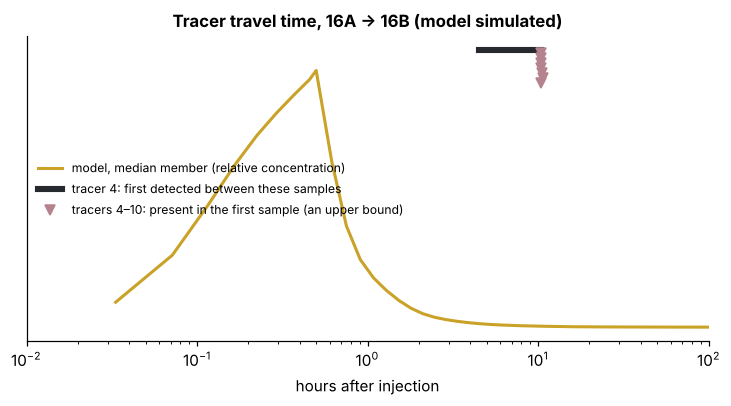

In [4]:
tc = pd.read_csv("data/tracers_2024_circulation.csv")
meas = []
for n, g in tc.groupby("tracer"):
    d = ft.tracer_detection(g.sample_t_h.values, g.injected_t_h.iloc[0], g.c_ppb.values)
    eng = next(x for x in E["tracers_measured"]["summary"] if x["tracer"] == n)
    assert abs(d["first_positive_h"] - eng["first_positive_h"]) < 1e-3 and abs(d["peak_h"] - eng["peak_h"]) < 1e-3
    assert abs(d["first_positive_h"] - eng["report_first_detection_h"]) < 0.3        # agrees with the report's Table 7
    meas.append({"tracer": n, **d})
meas = pd.DataFrame(meas); display(meas.round(1))
late = meas[meas.tracer >= 4]
Tm = ens["tracer"]
print(f"measured, tracers 4–10: first detection {late.first_positive_h.min():.1f}–{late.first_positive_h.max():.1f} h after injection "
      f"(tracer 4: between {meas.loc[meas.tracer == 4, 'last_clean_h'].item():.1f} and {meas.loc[meas.tracer == 4, 'first_positive_h'].item():.1f} h); "
      f"peak samples {late.peak_h.min():.0f}–{late.peak_h.max():.0f} h")
print(f"model (fracture porosity): 5 % of the tracer back after {pct(Tm['recovery_5pct_h'], '{:.2f}')} h; peak {pct(Tm['peak_time_h'], '{:.2f}')} h; "
      f"mean residence {pct(Tm['mean_residence_h'], '{:.1f}')} h; swept fracture pore volume {pct(Tm['pore_volume_m3'], '{:.0f}')} m³")
fac = {"lo": 4.5 / Tm["recovery_5pct_h"]["P50"], "hi": 10.5 / Tm["recovery_5pct_h"]["P50"]}
print(f"to arrive when measured, the model's transport porosity would have to be {fac['lo']:.0f}–{fac['hi']:.0f} × its fracture porosity")
c = E["median_member"]["tracer"]["curve"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(c["t_h"], c["c_rel"], color=GOLD, lw=2, label="model, median member (relative concentration)")
r4 = meas[meas.tracer == 4].iloc[0]
ax.plot([r4.last_clean_h, r4.first_positive_h], [1.08, 1.08], color=CHARCOAL, lw=4, label="tracer 4: first detected between these samples")
ax.plot(late.first_positive_h, 0.95 + 0.02 * (late.tracer - 4), "v", color=GRANITE, ms=6, label="tracers 4–10: present in the first sample (an upper bound)")
ax.set_xscale("log"); ax.set_xlim(0.01, 100); ax.set_xlabel("hours after injection"); ax.set_yticks([])
ax.set_title("Tracer travel time, 16A → 16B (model simulated)"); ax.legend(fontsize=8, loc="center left")
fig.savefig("figures/forge_tracers.png")

**Reading it.** In the model the water crosses in minutes; in the field the first tracer took at least 4.5 hours. The model's flow paths have too little pore space. That is expected for the way the apertures were set: one factor on the GDR 1646 apertures was fitted to the pressure, and the same factor sets the porosity. Hydraulic apertures from pressure are known to be much smaller than the apertures that hold the water (the transport apertures). The tracers put that ratio at tens. It hardly changes the heat results: with water and rock at the same temperature in a cell, the thermal front moves with the rock's heat capacity, not with the fracture volume. But it is a misfit, and it is reported as one.

## 3 · Pressure-dependent apertures: which rates are feasible

For each rate, the table gives the highest injector bottom-hole pressure over 30 years. It is compared with Shmin at the injector's top completion (17 kPa/m, GDR 1222). The two columns use the same calibrated network: apertures fixed, or apertures following Barton–Bandis.

,rate (kg/s),"max injector BHP, fixed apertures (MPa)",feasible (fixed),"max injector BHP, Barton–Bandis (MPa)",feasible (B–B),k multiplier at 16A (B–B),"T year 30 (°C, B–B)","breakthrough (years, B–B, 35 m)"
0,5,29.7 (29.1–30.1),20/20,30.9 (30.0–32.5),20/20,0.64 (0.43–0.81),153.2 (136.4–169.4),3.50 (1.88–5.48)
1,10,39.4 (38.2–40.2),19/20,41.0 (39.6–41.8),7/20,0.82 (0.68–0.94),129.2 (115.7–146.9),1.71 (0.90–2.68)
2,20,61.0 (58.7–62.4),0/20,52.7 (49.6–56.0),0/20,1.67 (1.43–2.64),106.4 (99.3–123.3),0.86 (0.43–1.30)
3,30,83.8 (80.8–86.0),0/20,67.2 (59.8–72.9),0/20,1.85 (1.47–3.74),95.8 (91.1–110.3),0.55 (0.30–0.81)
4,40,107.6 (102.4–110.0),0/20,82.6 (70.0–89.2),0/20,1.85 (1.47–3.74),89.2 (86.2–102.9),0.36 (0.21–0.56)


Shmin at the injector's top completion: 40.3 MPa; 16B held at 21.9 MPa
highest pressure-feasible rate: fixed apertures 10.5 (10.1–11.0) kg/s, Barton–Bandis 9.7 (9.3–10.5) kg/s


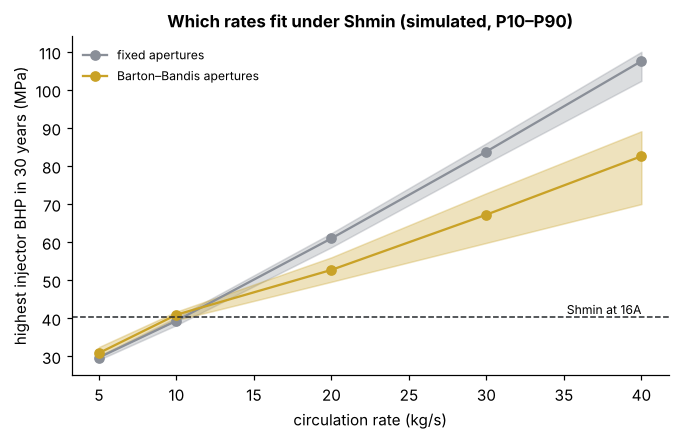

In [5]:
R = ens["rates"]
rows = []
for q in [k for k in R["barton_bandis"] if k != "max_feasible_rate_kg_s"]:
    a, b_ = R["constant_apertures"][q], R["barton_bandis"][q]
    n = ens["members"] - ens["failed"]
    rows.append({"rate (kg/s)": int(q), "max injector BHP, fixed apertures (MPa)": pct(a["injector_bhp_max_mpa"]), "feasible (fixed)": f"{a['feasible_members']}/{n}",
                 "max injector BHP, Barton–Bandis (MPa)": pct(b_["injector_bhp_max_mpa"]), "feasible (B–B)": f"{b_['feasible_members']}/{n}",
                 "k multiplier at 16A (B–B)": pct(b_["k_multiplier_injector"], "{:.2f}"), "T year 30 (°C, B–B)": pct(b_["T_prod_end_c"]),
                 "breakthrough (years, B–B, 35 m)": pct(b_["breakthrough_years"], "{:.2f}")})
display(pd.DataFrame(rows))
sh = R["barton_bandis"]["10"]["shmin_injector_mpa"]
print(f"Shmin at the injector's top completion: {sh:.1f} MPa; 16B held at {R['barton_bandis']['10']['producer_bhp_mpa']:.1f} MPa")
print(f"highest pressure-feasible rate: fixed apertures {pct(R['constant_apertures']['max_feasible_rate_kg_s'])} kg/s, "
      f"Barton–Bandis {pct(R['barton_bandis']['max_feasible_rate_kg_s'])} kg/s")
qs = [int(q) for q in R["barton_bandis"] if q != "max_feasible_rate_kg_s"]
fig, ax = plt.subplots(figsize=(7, 4))
for kind, c, lab in (("constant_apertures", GREY, "fixed apertures"), ("barton_bandis", GOLD, "Barton–Bandis apertures")):
    p = [R[kind][str(q)]["injector_bhp_max_mpa"] for q in qs]
    ax.fill_between(qs, [x["P10"] for x in p], [x["P90"] for x in p], color=c, alpha=0.3); ax.plot(qs, [x["P50"] for x in p], "o-", color=c, label=lab)
ax.axhline(sh, color=CHARCOAL, ls="--", lw=1); ax.text(qs[-1], sh + 0.8, "Shmin at 16A", ha="right", fontsize=8)
ax.set_xlabel("circulation rate (kg/s)"); ax.set_ylabel("highest injector BHP in 30 years (MPa)"); ax.legend(fontsize=8)
ax.set_title("Which rates fit under Shmin (simulated, P10–P90)")
fig.savefig("figures/forge_rates_feasible.png")

**Reading it.** Below the August rate, the fracture pressure is lower than in August, so the fractures close a little and the network gets tighter. At higher rates they open, but by less than the extra pressure needs. Cooling also makes the water near 16A more viscous year by year. So Barton–Bandis apertures **do not make the higher rates feasible**: the highest feasible rate stays near or below 10 kg/s. The August test itself ran 26.5 kg/s with the injector about 2.5 MPa above the recommended Shmin, which is where the field team saw signs of fracture growth. Growth is not modelled. Rates above the feasible rate stay what-if numbers.

## 4 · The full permeability tensor

The fractures are not aligned with the grid. In the stimulated cells the off-diagonal Oda terms are 0.3–0.4 of the diagonal. The engine now keeps them: a full-tensor finite-volume scheme, two-point flux plus cross-derivative terms. On a doublet with an exact answer it converges to the exact breakthrough (+0.7 %), while the diagonal-only scheme stays 39 % early. Here the median member is recalibrated with each scheme and grid.

In [6]:
F = E["full_tensor"]
rows = []
for r in F["runs"]:
    for q, f in r["forecast"].items():
        rows.append({"cells (m)": round(r["cell_m"], 1), "scheme": r["scheme"], "rate (kg/s)": int(q), "calibrated λ": round(r["stim_aperture_factor"], 3),
                     "breakthrough (years)": round(f["breakthrough_years"], 3), "T year 30 (°C)": round(f["T_prod_end_c"], 1),
                     "tracer 5 % back (h)": round(r["tracer"]["recovery_5pct_h"], 3)})
ft_tab = pd.DataFrame(rows); display(ft_tab)
B = E["benchmarks"]["anisotropic_doublet"]
print(f"benchmark (exact anisotropic doublet): full tensor {B['full_vs_exact']:+.1%}, diagonal {B['diagonal_vs_exact']:+.1%} (converged breakthrough)")

,cells (m),scheme,rate (kg/s),calibrated λ,breakthrough (years),T year 30 (°C),tracer 5 % back (h)
0,35.0,diagonal (TPFA),10,0.150,0.542,119.0,0.125
1,35.0,diagonal (TPFA),20,0.150,0.262,103.8,0.125
2,35.0,full tensor (TPFA + cross terms),10,0.147,0.586,117.4,0.130
3,35.0,full tensor (TPFA + cross terms),20,0.147,0.283,102.2,0.130
4,23.3,diagonal (TPFA),10,0.167,0.862,120.8,0.149
5,23.3,diagonal (TPFA),20,0.167,0.382,102.4,0.149
6,23.3,full tensor (TPFA + cross terms),10,0.161,0.856,119.2,0.147
7,23.3,full tensor (TPFA + cross terms),20,0.161,0.378,101.9,0.147


benchmark (exact anisotropic doublet): full tensor +0.7%, diagonal -39.5% (converged breakthrough)


## 5 · The upscaling check

The usual practice is a coarse model (here 70 m cells), with the fracture tensor averaged into each cell and Peaceman well indices, recalibrated on the test. The fine model has 23.3 m cells. Both use the same fractures: same seed, and natural discs of 35 m and more placed one by one. The KAI coarse model takes its transmissibilities and well indices from the fine model's well-pair solution (global plus near-well upscaling) and is **not** recalibrated. Breakthrough change = coarse / fine − 1, member by member.

,rate (kg/s),coarse model,fine breakthrough (years),coarse breakthrough (years),breakthrough change,T year 30 change (°C)
0,10,"70 m, usual (Oda average + Peaceman, recalibra...",1.67 (1.28–1.85),2.04 (1.12–2.78),+25 % (-32 %–+62 %),+10.8 (+3.1–+14.2)
1,10,"70 m, KAI (global + near-well upscaling)",1.67 (1.28–1.85),2.54 (1.35–3.21),+54 % (-26 %–+115 %),+2.4 (-0.0–+5.1)
2,40,"70 m, usual (Oda average + Peaceman, recalibra...",0.36 (0.28–0.39),0.49 (0.27–0.68),+39 % (-26 %–+84 %),+5.9 (+0.4–+8.8)
3,40,"70 m, KAI (global + near-well upscaling)",0.36 (0.28–0.39),0.60 (0.32–0.76),+72 % (-16 %–+141 %),-3.6 (-4.6–-1.3)


12/12 members; August pressure difference: target 20.9 (20.9–20.9) MPa, KAI coarse (not recalibrated) 17.0 (16.3–18.3) MPa, usual coarse before recalibration 13.2 (11.5–14.7) MPa


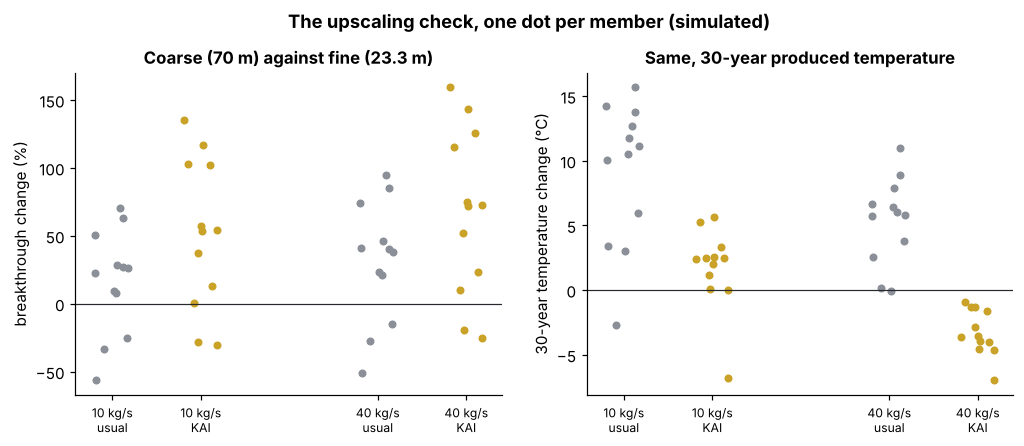

In [7]:
U = E["upscaling"]
rows = []
for q, d in U["rates"].items():
    for model, lab in (("coarse_usual", "70 m, usual (Oda average + Peaceman, recalibrated)"), ("coarse_kai", "70 m, KAI (global + near-well upscaling)")):
        rows.append({"rate (kg/s)": int(q), "coarse model": lab, "fine breakthrough (years)": pct(d["fine"]["breakthrough_years"], "{:.2f}"),
                     "coarse breakthrough (years)": pct(d[model]["breakthrough_years"], "{:.2f}"),
                     "breakthrough change": pct({k: d[model]["breakthrough_change"][k] * 100 for k in ("P10", "P50", "P90")}, "{:+.0f} %"),
                     "T year 30 change (°C)": pct(d[model]["T30_change_c"], "{:+.1f}")})
display(pd.DataFrame(rows))
print(f"{U['members'] - U['failed']}/{U['members']} members; August pressure difference: target {pct(U['august_dp_target_mpa'])} MPa, "
      f"KAI coarse (not recalibrated) {pct(U['coarse_kai_august_dp_mpa'])} MPa, usual coarse before recalibration {pct(U['coarse_usual_uncalibrated_august_dp_mpa'])} MPa")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, q in enumerate(U["rates"]):
    for j, (model, c) in enumerate((("coarse_usual", GREY), ("coarse_kai", GOLD))):
        vals = [m["rates"][q][model]["breakthrough_change"] * 100 for m in E["upscaling_members"] if m["ok"] and m["rates"][q][model]["breakthrough_change"] is not None]
        ax[0].scatter(np.full(len(vals), i * 3 + j) + np.random.default_rng(j).uniform(-0.2, 0.2, len(vals)), vals, color=c, s=18)
        vals = [m["rates"][q][model]["T30_change_c"] for m in E["upscaling_members"] if m["ok"]]
        ax[1].scatter(np.full(len(vals), i * 3 + j) + np.random.default_rng(j).uniform(-0.2, 0.2, len(vals)), vals, color=c, s=18)
for a_, lab in zip(ax, ("breakthrough change (%)", "30-year temperature change (°C)")):
    a_.axhline(0, color=CHARCOAL, lw=0.8); a_.set_ylabel(lab)
    a_.set_xticks([0, 1, 3, 4]); a_.set_xticklabels([f"{q} kg/s\n{m}" for q in U["rates"] for m in ("usual", "KAI")], fontsize=8)
ax[0].set_title("Coarse (70 m) against fine (23.3 m)"); ax[1].set_title("Same, 30-year produced temperature")
fig.suptitle("The upscaling check, one dot per member (simulated)", y=1.03, fontweight="bold")
fig.savefig("figures/forge_upscaling.png")

## How much the breakthrough time depends on the grid (Barton–Bandis forecasts)

In [8]:
G = E["grid_convergence"]
rows = []
for q, g in G["rates"].items():
    b = g["breakthrough_years"]
    rows.append({"rate (kg/s)": int(q), **{f"{r['cell_m']:.1f} m": round(r["breakthrough_years"], 3) for r in g["runs"]},
                 "converged ± GCI (years)": f"{b['converged']:.3f} ± {b['error_abs']:.3f}", "observed order": None if b["order"] is None else round(b["order"], 2),
                 "T year 30 converged (°C)": f"{g['T_prod_end_c']['converged']:.1f} ± {g['T_prod_end_c']['error_abs']:.1f}"})
display(pd.DataFrame(rows))

,rate (kg/s),52.5 m,35.0 m,23.3 m,converged ± GCI (years),observed order,T year 30 converged (°C)
0,10,2.672,1.647,1.366,1.260 ± 0.133,3.19,129.6 ± 4.4


## Published numbers

In [9]:
now = {}
for k in ("cooling_implied_c", "T_bottom_implied_c", "injector_bhp_mpa", "injector_T_bottom_c"):
    for p in ("P10", "P50", "P90"):
        now[f"wb_{k}_{p}"] = W[k][p]
for p in ("P10", "P50", "P90"):
    now[f"Tmisfit_bb_{p}"] = V["barton_bandis"]["T_misfit_bottomhole_c"][p]
    now[f"tracer_rec5_{p}"] = Tm["recovery_5pct_h"][p]
    for kind in ("constant_apertures", "barton_bandis"):
        now[f"maxrate_{kind}_{p}"] = R[kind]["max_feasible_rate_kg_s"][p]
    for q in U["rates"]:
        for model in ("coarse_usual", "coarse_kai"):
            now[f"ups_{q}_{model}_{p}"] = U["rates"][q][model]["breakthrough_change"][p]
now["dts_delta"] = dT_dts; now["dts_model_P50"] = W["dts_section_delta_model_c"]["P50"]; now["dts_bound_P50"] = W["dts_section_delta_upper_bound_c"]["P50"]
for q in G["rates"]:
    now[f"bt_converged_{q}"] = G["rates"][q]["breakthrough_years"]["converged"]; now[f"bt_gci_{q}"] = G["rates"][q]["breakthrough_years"]["error_abs"]
published = {'wb_cooling_implied_c_P10': 12.324181844903322, 'wb_cooling_implied_c_P50': 13.38779549327974, 'wb_cooling_implied_c_P90': 14.352029587078594, 'wb_T_bottom_implied_c_P10': 199.97403647313038, 'wb_T_bottom_implied_c_P50': 202.88457132593163, 'wb_T_bottom_implied_c_P90': 205.85298138010114, 'wb_injector_bhp_mpa_P10': 42.84779262753177, 'wb_injector_bhp_mpa_P50': 42.853609125419034, 'wb_injector_bhp_mpa_P90': 42.85602229315068, 'wb_injector_T_bottom_c_P10': 41.154958863684676, 'wb_injector_T_bottom_c_P50': 42.04631144266385, 'wb_injector_T_bottom_c_P90': 44.154343137155415, 'Tmisfit_bb_P10': 9.725390449148216, 'tracer_rec5_P10': 0.12557416196561144, 'maxrate_constant_apertures_P10': 10.060463269365748, 'maxrate_barton_bandis_P10': 9.277143465586944, 'ups_10_coarse_usual_P10': -0.3236418196892601, 'ups_10_coarse_kai_P10': -0.25596534214453714, 'ups_40_coarse_usual_P10': -0.2647945235069995, 'ups_40_coarse_kai_P10': -0.16486737273423846, 'Tmisfit_bb_P50': 11.172836391230462, 'tracer_rec5_P50': 0.1915658780604741, 'maxrate_constant_apertures_P50': 10.461192081923468, 'maxrate_barton_bandis_P50': 9.697774906884248, 'ups_10_coarse_usual_P50': 0.24731081716239411, 'ups_10_coarse_kai_P50': 0.5395396276909319, 'ups_40_coarse_usual_P50': 0.39294875070419166, 'ups_40_coarse_kai_P50': 0.7242740813217983, 'Tmisfit_bb_P90': 12.605435859655586, 'tracer_rec5_P90': 0.43779972998185185, 'maxrate_constant_apertures_P90': 11.044794649785873, 'maxrate_barton_bandis_P90': 10.502523471591307, 'ups_10_coarse_usual_P90': 0.6220211771833027, 'ups_10_coarse_kai_P90': 1.152485890986813, 'ups_40_coarse_usual_P90': 0.844051087172596, 'ups_40_coarse_kai_P90': 1.414980244087259, 'dts_delta': 18.389999999999986, 'dts_model_P50': 5.809218136095112, 'dts_bound_P50': 7.1533351444909385, 'bt_converged_10': 1.2596630987830928, 'bt_gci_10': 0.13311331158756687}
for k, v in published.items():
    x = now[k]
    if isinstance(v, str) or isinstance(x, str) or v is None or x is None:
        assert x == v, (k, x, v)
    else:
        assert abs(x - v) <= 0.02 * abs(v) + 0.01, (k, x, v)
pathlib.Path("results/nb4_upscaling_check.json").write_text(json.dumps({"published": now}, indent=1))
print(f"all {len(published)} published numbers reproduced")

all 41 published numbers reproduced


## What this says, and what it does not

* **The temperature misfit is mostly in the wellbore, and partly in the reservoir model.** The wellbore model cools the produced water by 13.4 °C (P10–P90 12.3–14.4) on its way up 16B. So the measured 189.8 °C at the wellhead means 202.9 °C (200.0–205.9) at the bottom hole. The model gives 214.1 °C there, so +11.2 °C (+9.7 to +12.6) of the notebook 3 misfit is left in the reservoir model. Two causes are likely. Water may reach 16B through fast, thin paths where it does not warm fully, because the rock next to a fracture cools first (the model assumes water and rock in a cell are at one temperature). Or the 3-D temperature model may be a little hot at 16B.
* **The fibre data cannot settle it.** The 16B DTS shows a step and a drift, and its deep gradient (+18.4 °C over 6,040 ft) is 2.6 times the energy-balance upper bound. We report it, but we do not fit to it.
* **The tracers travel slower than the model's water.** From tracer 4 on, tracers were first seen within 10.5 hours of injection, and tracer 4 not before 4.5 hours. In the model, 5 % of a pulse is back after 0.19 h (0.13–0.44). The pore space that carries the water is 23–55 times the model's fracture porosity. Pressure-fitted (hydraulic) apertures are expected to be much smaller than transport apertures, and the tracers measure how much smaller.
* **Pressure-dependent apertures do not unlock higher rates.** With Barton–Bandis apertures, the highest rate that keeps 16A at or below Shmin for 30 years is 9.7 kg/s (9.3–10.5). With fixed apertures it is 10.5 (10.1–11.0). At lower rates than August the fractures close a little; at higher rates they open, but too little. Rates of 20–40 kg/s stay what-if numbers unless the network is stimulated further. No fracture growth is modelled.
* **The full tensor matters little here.** Recalibrated, it changes λ by 2–4 %, breakthrough by −1 to +8 % and the 30-year temperature by about −1.5 °C. On the exact anisotropic doublet, the diagonal-only scheme is 40 % early and the full tensor is within 1 %.
* **The upscaling check.** On 70 m cells, early breakthrough is not reliable whichever way the coarse model is built. Member by member it moves by −32 % to +62 % (usual practice) and −26 % to +115 % (KAI upscaling) at 10 kg/s. The 30-year answer is different. The usual coarse model, recalibrated on the test, is optimistic by +10.8 °C (+3.1 to +14.2) at 10 kg/s. The KAI coarse model is not recalibrated; it stays within +2.4 °C (0.0 to +5.1) and holds 81 % of the measured injection pressure difference. Upscaling the flow (transmissibilities and well indices) fixes pressure and long-term heat. It does not fix the resolution of a sharp thermal front.
* **Breakthrough at 10 kg/s (Barton–Bandis), grid-converged:** 1.26 ± 0.13 years for the median member. The 35 m ensemble value of 1.71 years (0.90–2.68) is about 30 % late.

**Limits.** Equivalent continuum with local thermal equilibrium. Barton–Bandis with assumed stiffness and closure ranges and σn = Shmin for every stimulated fracture. No fracture growth, shear dilation or thermal opening. Steady flow for the tracer, with no dispersion beyond the numerical one. Single-phase water in the wellbore. The DTS is used only as a check, and it fails that check.

*References:* Hasan, A. R. and Kabir, C. S. (1991). Heat transfer during two-phase flow in wellbores. SPE-22866 · Barton, N., Bandis, S. and Bakhtar, K. (1985). Strength, deformation and conductivity coupling of rock joints. Int. J. Rock Mech. 22(3) · Oda, M. (1985). Permeability tensor for discontinuous rock masses. Géotechnique 35(4) · Ding, Y. (1995). Scaling-up in the vicinity of wells in heterogeneous field. SPE-29137 · Chen, Y., Durlofsky, L. J. et al. (2003). A coupled local–global upscaling approach. Adv. Water Resour. 26 · Guo, Q., Oliver, J. and Shokanov, T. (2024). GDR 1701, DOI 10.15121/2507443.